# Color Spaces, Histograms, and Moments

The numbers in an image file are measurements of light, not of perception. The book section
*Color Features* draws two lessons from this. First, we must transform the numbers before their
distances become meaningful. Second, a feature must decide which differences to ignore: a shadow
changes the measured color of a surface, but not the surface itself. This notebook follows the
section step by step on its three photos: the Matterhorn, the Taj Mahal in Agra, and Roger Federer
at Wimbledon. At the end, we send the Matterhorn photo as a query against four candidates and see
which differences each feature ignores.

**Learning goals:**
- See why equal sRGB distances are not equal perceived differences, and why the conversion to Lab
  must undo the gamma encoding
- Separate the hue from the brightness with HSV, and find the pixels that have no meaningful hue
- Build color histograms over the 125 Lab reference colors of the book and over other vocabularies
- Compare histograms with the L1, L2, quadratic, and intersection measures and reproduce the book's values
- Compute the 15 color moments, rescale them, and see where a few statistics fail
- Test which differences global color features ignore: a shadow, and the position of the pixels

**Prerequisites:** demo ch09-02 (the color histogram as the counterpart of a term vector),
Chapter 6, section *Distance and Similarity* (Gaussian normalization)

**Data:** the three photos of the book section, from Wikimedia Commons under CC0, CC BY, and
CC BY-SA licenses, stored in `data/images/`; `data/images/SOURCES.md` lists authors and licenses.
The notebook needs no downloads and runs offline.

## Setup

`ch10_features.py` holds the fixed formulas of this chapter: loading the photos and converting
sRGB to CIE Lab and back (the formulas of appendix E.2 of the book). Everything that this notebook
teaches is defined in the notebook itself.

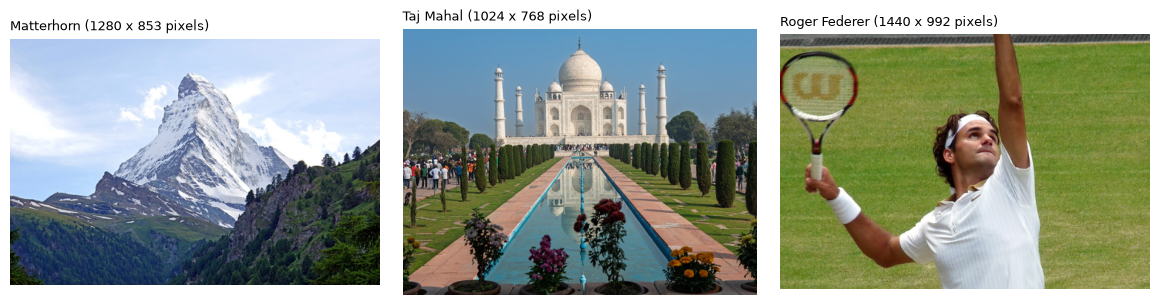

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.ticker import PercentFormatter

from shared.display import print_table, display_md
from ch10_features import PHOTOS, load_photos, rgb_to_lab, lab_to_rgb, thumbnail, show_images

photos = load_photos()          # name -> sRGB pixels, array of height x width x 3, values 0 to 255
titles = {name: title for name, (_, title) in PHOTOS.items()}
lab = {name: rgb_to_lab(p) for name, p in photos.items()}      # the same pixels in CIE Lab

show_images([thumbnail(p) for p in photos.values()],
            [f"{titles[n]} ({p.shape[1]} x {p.shape[0]} pixels)" for n, p in photos.items()])

## 1. Why the Color Space Matters

### Four colors, three equal steps

The book shows four colors where one channel changes by 100 units from one box to the next. In
sRGB, the three steps have the same Euclidean distance of 100. We convert the four colors to Lab
and measure again. The conversion has one step that is easy to miss: sRGB values are
gamma-encoded and must be linearized before they are converted to CIE XYZ and then to Lab. The
last column skips this step, to show what the mistake does.

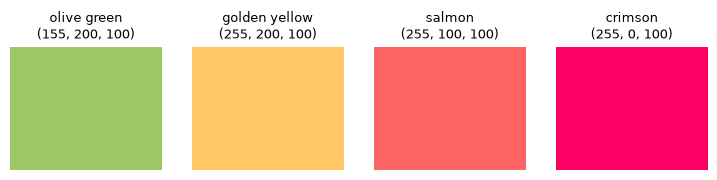

| Step                         |   sRGB distance |   Lab distance |   Lab distance without linearization |
|:-----------------------------|----------------:|---------------:|-------------------------------------:|
| olive green to golden yellow |           100.0 |           42.7 |                                 20.0 |
| golden yellow to salmon      |           100.0 |           59.8 |                                 40.0 |
| salmon to crimson            |           100.0 |           27.7 |                                 67.4 |

In [2]:
boxes = {"olive green": (155, 200, 100), "golden yellow": (255, 200, 100),
         "salmon": (255, 100, 100), "crimson": (255, 0, 100)}
box_rgb = np.array(list(boxes.values()), float)
box_lab = rgb_to_lab(box_rgb)
box_lab_wrong = rgb_to_lab(box_rgb, linearize=False)        # gamma encoding not undone

fig, axes = plt.subplots(1, 4, figsize=(9, 1.6))
for ax, (name, rgb) in zip(axes, boxes.items()):
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, color=np.array(rgb) / 255))
    ax.set_title(f"{name}\n{rgb}", fontsize=9)
    ax.axis("off")
plt.show()

names = list(boxes)
step = lambda x, i: np.linalg.norm(x[i + 1] - x[i])
print_table([[f"{names[i]} to {names[i + 1]}", step(box_rgb, i), step(box_lab, i), step(box_lab_wrong, i)]
             for i in range(3)],
            headers=["Step", "sRGB distance", "Lab distance", "Lab distance without linearization"],
            floatfmt=".1f")

In Lab, the three steps differ, and they differ the way we see them: the step from salmon to
crimson is less than half as large as the step before it. Without the linearization, the
conversion treats the gamma-encoded values as if they were amounts of light. The order of the
steps then flips, and the step from salmon to crimson becomes the largest of the three. The
mistake raises no error. It produces distances that look plausible and are wrong.

### The Lab and HSV channels of a photo

**CIE Lab** describes a color by its lightness $L$ from 0 (black) to 100 (white) and two
chromaticity axes: $a$ runs from green (negative) to red (positive), $b$ from blue (negative) to
yellow (positive), and grays lie at $a = b = 0$. **HSV** turns the RGB cube into a cylinder: the
hue $H$ is an angle, the saturation $S$ the distance from the gray axis, and the value $V$ the
height. `matplotlib.colors.rgb_to_hsv` returns all three between 0 and 1; we multiply the hue by
360 to get degrees.

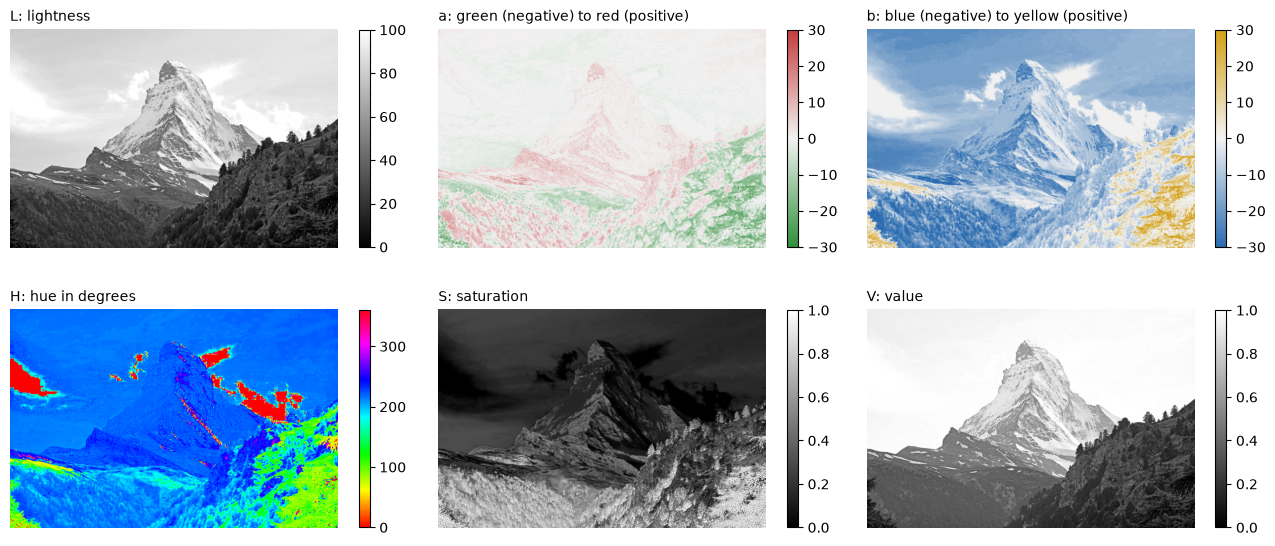

In [3]:
m = photos["matterhorn"]
hsv_m = mcolors.rgb_to_hsv(m / 255)
hue_m = hsv_m[..., 0] * 360

green_red = mcolors.LinearSegmentedColormap.from_list("a", ["#2f8f3a", "#f2f2f2", "#c43c3c"])
blue_yellow = mcolors.LinearSegmentedColormap.from_list("b", ["#2b6cb0", "#f2f2f2", "#d4a017"])
panels = [(lab["matterhorn"][..., 0], "L: lightness", dict(cmap="gray", vmin=0, vmax=100)),
          (lab["matterhorn"][..., 1], "a: green (negative) to red (positive)", dict(cmap=green_red, vmin=-30, vmax=30)),
          (lab["matterhorn"][..., 2], "b: blue (negative) to yellow (positive)", dict(cmap=blue_yellow, vmin=-30, vmax=30)),
          (hue_m, "H: hue in degrees", dict(cmap="hsv", vmin=0, vmax=360)),
          (hsv_m[..., 1], "S: saturation", dict(cmap="gray", vmin=0, vmax=1)),
          (hsv_m[..., 2], "V: value", dict(cmap="gray", vmin=0, vmax=1))]

fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, (channel, title, kw) in zip(axes.ravel(), panels):
    im = ax.imshow(channel, **kw)
    ax.set_title(title, fontsize=10, loc="left")
    ax.axis("off")
    fig.colorbar(im, ax=ax, shrink=0.75)
plt.tight_layout()
plt.show()

The $L$ channel shows the sky and the sunlit snow as bright and the forest at the bottom as dark.
The $b$ channel is negative, that is blue, in the sky and in the snow in shade, and close to zero
in the white clouds. The $a$ channel stays close to zero in the sky and on the mountain; only the
forest shows some green. The hue channel shows the clouds as red patches next to a blue sky.
Their pixels are nearly gray, as the dark areas of the $S$ channel show, and the hue of a nearly
gray pixel is close to an arbitrary angle.

### Hue ignores a shadow

HSV is not perceptually uniform, but it separates the hue from the brightness. The book's example
is a red car in the sun and in the shade: nearly the same hue, but a different value. We test
this with a darker copy of the Matterhorn photo, in which every sRGB value is multiplied by 0.6,
as if a cloud had covered the sun. Two details need care. Hue is an angle, so we average it as an
angle: 350° and 10° average to 0°, not to 180°. And pixels that are nearly gray or very dark have
no meaningful hue, so we leave them out. The book does not fix thresholds; we use a saturation
below 0.15 or a value below 0.10.

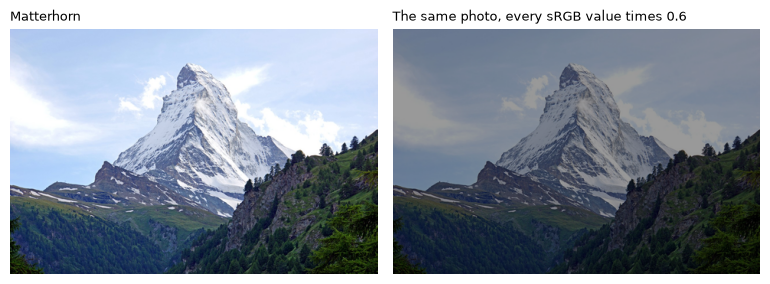

| Channel (mean over the pixels)           |   Matterhorn |   Darker copy |
|:-----------------------------------------|-------------:|--------------:|
| H: hue (circular mean of colored pixels) |       211.20 |        211.20 |
| S: saturation                            |         0.29 |          0.29 |
| V: value                                 |         0.68 |          0.41 |
| L: lightness                             |        60.95 |         37.63 |
| a: green to red                          |        -0.66 |         -0.49 |
| b: blue to yellow                        |       -11.54 |         -7.60 |

In [4]:
GRAY_S, GRAY_V = 0.15, 0.10         # below these thresholds a pixel counts as gray (our choice)

def has_hue(hsv):
    """True where a pixel is saturated and bright enough for its hue to mean something."""
    return (hsv[..., 1] >= GRAY_S) & (hsv[..., 2] >= GRAY_V)

def circular_mean(degrees):
    """Mean of angles: the direction of the mean unit vector."""
    rad = np.radians(degrees)
    return np.degrees(np.arctan2(np.sin(rad).mean(), np.cos(rad).mean())) % 360

darker = np.round(m * 0.6).astype(np.uint8)          # the same scene with less light
hsv_d = mcolors.rgb_to_hsv(darker / 255)
lab_d = rgb_to_lab(darker)
colored = has_hue(hsv_m) & has_hue(hsv_d)            # pixels with a meaningful hue in both photos

show_images([thumbnail(m), thumbnail(darker)], ["Matterhorn", "The same photo, every sRGB value times 0.6"])
print_table([["H: hue (circular mean of colored pixels)", circular_mean(hue_m[colored]),
              circular_mean(hsv_d[..., 0][colored] * 360)],
             ["S: saturation", hsv_m[..., 1].mean(), hsv_d[..., 1].mean()],
             ["V: value", hsv_m[..., 2].mean(), hsv_d[..., 2].mean()],
             ["L: lightness", lab["matterhorn"][..., 0].mean(), lab_d[..., 0].mean()],
             ["a: green to red", lab["matterhorn"][..., 1].mean(), lab_d[..., 1].mean()],
             ["b: blue to yellow", lab["matterhorn"][..., 2].mean(), lab_d[..., 2].mean()]],
            headers=["Channel (mean over the pixels)", "Matterhorn", "Darker copy"], floatfmt=".2f")

Hue and saturation stay where they were; only the value shrinks to 60%. In Lab, all three
channels change: the lightness drops, and $b$ moves toward zero, because a darker blue is a less
vivid blue. A Lab feature therefore sees the shadow as a large change. A feature built from the
hue alone ignores it, which is what the payoff at the end of this notebook will show on whole
histograms.

### Pixels without a hue

How many pixels fall below the thresholds depends on the photo. Below, every pixel with a
meaningful hue is drawn in its pure hue, at full saturation and value. Every other pixel is drawn
in gray.

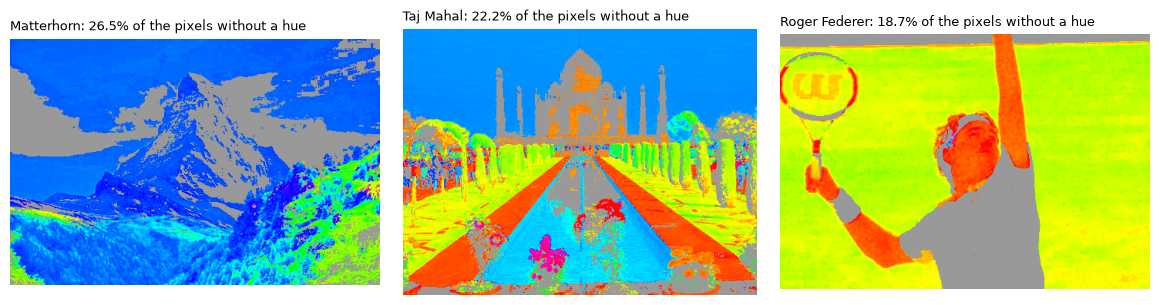

In [5]:
def hue_view(rgb):
    """Each pixel in its pure hue (full saturation and value), or mid-gray if it has no meaningful hue."""
    hsv = mcolors.rgb_to_hsv(rgb / 255)
    pure = mcolors.hsv_to_rgb(np.stack([hsv[..., 0], np.ones_like(hsv[..., 0]), np.ones_like(hsv[..., 0])], -1))
    return np.where(has_hue(hsv)[..., None], pure, 0.6)

thumbs = {n: thumbnail(p) for n, p in photos.items()}
gray_share = {n: 1 - has_hue(mcolors.rgb_to_hsv(p / 255)).mean() for n, p in photos.items()}
show_images([hue_view(t) for t in thumbs.values()],
            [f"{titles[n]}: {gray_share[n]:.1%} of the pixels without a hue" for n in thumbs])

The clouds, the white marble, and the white tennis shirt have no meaningful hue. Most of the
Matterhorn's snow lies in shade and is slightly blue, so it keeps a hue. HSV-based features treat
the gray pixels as gray levels instead of assigning them a hue.

## 2. Color Histograms

### 125 reference colors in Lab

A color histogram needs a fixed set of **reference colors**, which play the role of the
vocabulary in text retrieval. The system assigns each pixel to its reference color, counts the
pixels per reference color, and divides the counts by the number of pixels. The book divides Lab
into ranges of 20 units on each axis: five ranges for $L$ from 0 to 100, and five ranges each for
$a$ and $b$ from -50 to 50, where values beyond the outer ranges are assigned to them. This gives
$5 \times 5 \times 5 = 125$ reference colors, numbered by lightness first, then $a$, then $b$.

In [6]:
def lab_bin(lab, step=20):
    """Index of the reference color of each Lab value: ranges of `step` units on L (0 to 100) and on
    a and b (-50 to 50); values beyond the outer ranges belong to the outer ranges."""
    n = 100 // step
    L = np.clip(lab[..., 0] // step, 0, n - 1).astype(int)
    a = np.clip((lab[..., 1] + 50) // step, 0, n - 1).astype(int)
    b = np.clip((lab[..., 2] + 50) // step, 0, n - 1).astype(int)
    return (L * n + a) * n + b

def lab_reference_colors(step=20):
    """Lab centers of the reference colors, in the order of lab_bin."""
    n = 100 // step
    cL = (np.arange(n) + 0.5) * step
    cab = -50 + (np.arange(n) + 0.5) * step
    return np.array([(l, a, b) for l in cL for a in cab for b in cab])

def histogram(bins, n_bins):
    """Share of the pixels per reference color: the counts divided by the number of pixels."""
    h = np.bincount(bins.ravel(), minlength=n_bins).astype(float)
    return h / h.sum()

centers = lab_reference_colors()
center_rgb = lab_to_rgb(centers)                     # how each reference color looks on screen
H = {n: histogram(lab_bin(l), len(centers)) for n, l in lab.items()}

To see what a histogram counts, we replace every pixel by its reference color. The bar charts
show the histograms over the reference colors that at least one photo uses, in the same order in
every row and grouped by lightness from dark to light. Each bar has the color of its reference
color, so a bar at the same position means the same color in all three photos.

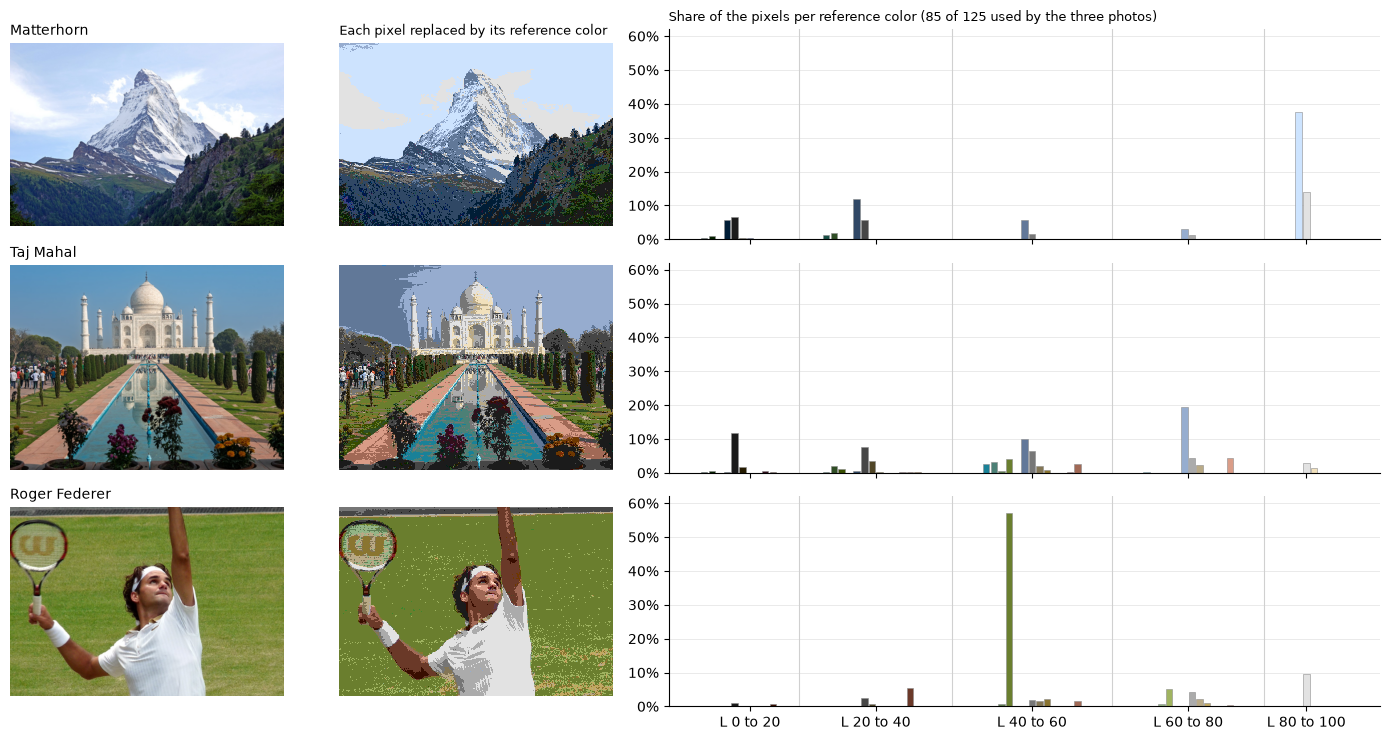

In [7]:
used = np.flatnonzero(sum(H.values()) > 0)           # reference colors used by at least one photo
L_range = used // 25                                  # lightness range (0 to 4) of each used color

fig, axes = plt.subplots(3, 3, figsize=(14, 7.5), gridspec_kw=dict(width_ratios=[1, 1, 2.6]))
for r, (n, t) in enumerate(thumbs.items()):
    axes[r, 0].imshow(t)
    axes[r, 1].imshow(center_rgb[lab_bin(rgb_to_lab(t))], interpolation="nearest")
    axes[r, 0].set_title(titles[n], fontsize=10, loc="left")
    for ax in axes[r, :2]:
        ax.axis("off")
    ax = axes[r, 2]
    ax.bar(range(len(used)), H[n][used], width=0.85, color=center_rgb[used], edgecolor="#8c8c8c", linewidth=0.4)
    for i in np.flatnonzero(np.diff(L_range)) + 0.5:
        ax.axvline(i, color="#d0d0d0", lw=0.8)
    ax.set_xticks([np.flatnonzero(L_range == k).mean() for k in np.unique(L_range)])
    ax.set_xticklabels([f"L {20 * k} to {20 * k + 20}" for k in np.unique(L_range)] if r == 2 else [])
    ax.set_ylim(0, 0.62)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e6e6e6", lw=0.6)
    ax.set_axisbelow(True)
axes[0, 1].set_title("Each pixel replaced by its reference color", fontsize=9, loc="left")
axes[0, 2].set_title(f"Share of the pixels per reference color ({len(used)} of 125 used by the three photos)",
                     fontsize=9, loc="left")
plt.tight_layout()
plt.show()

In [8]:
rows = []
for n, h in H.items():
    for rank, i in enumerate(np.argsort(-h)[:3], 1):
        rows.append([titles[n] if rank == 1 else "", f"{(h > 0).sum()} of 125" if rank == 1 else "", rank,
                     "L {:.0f}, a {:.0f}, b {:.0f}".format(*centers[i]), f"{h[i]:.1%}"])
print_table(rows, headers=["Photo", "Reference colors used", "Rank", "Reference color (Lab center)", "Share of pixels"])

| Photo         | Reference colors used   |   Rank | Reference color (Lab center)   | Share of pixels   |
|:--------------|:------------------------|-------:|:-------------------------------|:------------------|
| Matterhorn    | 40 of 125               |      1 | L 90, a 0, b -20               | 37.6%             |
|               |                         |      2 | L 90, a 0, b 0                 | 14.0%             |
|               |                         |      3 | L 30, a 0, b -20               | 12.0%             |
| Taj Mahal     | 77 of 125               |      1 | L 70, a 0, b -20               | 19.4%             |
|               |                         |      2 | L 10, a 0, b 0                 | 11.9%             |
|               |                         |      3 | L 50, a 0, b -20               | 10.0%             |
| Roger Federer | 53 of 125               |      1 | L 50, a -20, b 40              | 57.2%             |
|               |                         |      2 | L 90, a 0, b 0                 | 9.6%              |
|               |                         |      3 | L 30, a 20, b 20               | 5.4%              |

The Matterhorn photo uses 40 of the 125 reference colors, and three of them cover almost two
thirds of its pixels: the light sky blue at $L = 90, b = -20$ (the sky and the snow in shade),
white (the sunlit snow and the clouds), and a dark blue-gray (the forest slopes in shadow). The
Taj Mahal photo contains the same kinds of colors, but they fall into different bins. Its sky is
darker, so it lands one and two lightness ranges lower, and at the position of the Matterhorn's
largest bin the Taj Mahal histogram is empty. The Federer photo is dominated by a single
yellowish green: the grass.

### Other reference colors

The choice of reference colors decides what the histogram can distinguish. The book names three
alternatives. Equal ranges in RGB, four per channel, give $4^3 = 64$ reference colors. Smaller
ranges in Lab give more reference colors: ranges of 10 units give $10^3 = 1000$, the upper end of
practical systems. And in HSV, the hue circle can be split into sectors of similar-looking hues,
with boundaries at 22°, 45°, 70°, 155°, 186°, 278°, and 330°. For the hue vocabulary we use the
seven sectors alone and add one bin for all pixels without a meaningful hue, which gives eight
reference colors. (The book's HSV vocabulary also splits the value into nine ranges, which gives
$7 \times 9 = 63$; *Try it yourself* comes back to this.)

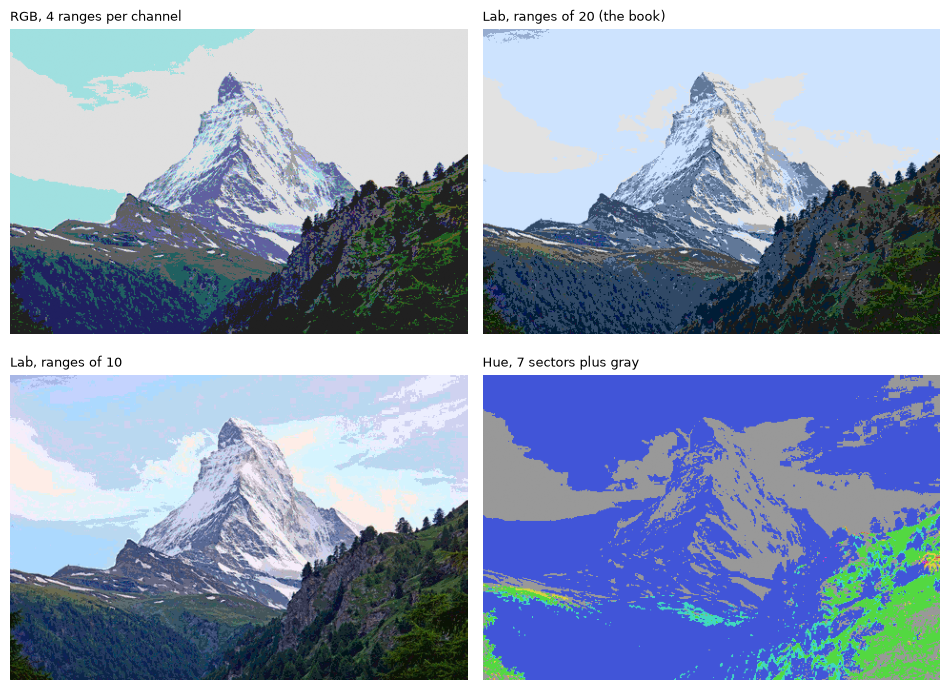

| Vocabulary                   |   Reference colors |   Used by the Matterhorn photo | Largest bin   |
|:-----------------------------|-------------------:|-------------------------------:|:--------------|
| RGB, 4 ranges per channel    |                 64 |                             26 | 41.3%         |
| Lab, ranges of 20 (the book) |                125 |                             40 | 37.6%         |
| Lab, ranges of 10            |               1000 |                            187 | 15.6%         |
| Hue, 7 sectors plus gray     |                  8 |                              8 | 64.2%         |

In [9]:
def rgb_bin(rgb, k=4):
    """Index of the reference color for k equal ranges per RGB channel (k**3 reference colors)."""
    q = (np.asarray(rgb) // (256 // k)).astype(int)
    return (q[..., 0] * k + q[..., 1]) * k + q[..., 2]

def rgb_reference_colors(k=4):
    c = (np.arange(k) + 0.5) * 256 / k
    return np.array([(r, g, b) for r in c for g in c for b in c])

HUE_BOUNDS = [22, 45, 70, 155, 186, 278, 330]         # sector boundaries in degrees, from the book
HUE_CENTERS = [356, 33.5, 57.5, 112.5, 170.5, 232, 304]   # sector 0 (red) wraps around 0 degrees

def hue_bin(rgb):
    """Seven hue sectors (0 = red, from 330 to 22 degrees), plus bin 7 for pixels without a hue."""
    hsv = mcolors.rgb_to_hsv(np.asarray(rgb) / 255)
    sector = np.searchsorted(HUE_BOUNDS, hsv[..., 0] * 360, side="right") % 7
    return np.where(has_hue(hsv), sector, 7)

hue_rgb = np.vstack([mcolors.hsv_to_rgb([[c / 360, 0.7, 0.85] for c in HUE_CENTERS]), [[0.6, 0.6, 0.6]]])
centers_fine = lab_reference_colors(step=10)

# name -> (bin function, display color of each reference color, Lab center of each reference color)
vocabularies = {
    "RGB, 4 ranges per channel": (rgb_bin, rgb_reference_colors() / 255, rgb_to_lab(rgb_reference_colors())),
    "Lab, ranges of 20 (the book)": (lambda p: lab_bin(rgb_to_lab(p)), center_rgb, centers),
    "Lab, ranges of 10": (lambda p: lab_bin(rgb_to_lab(p), step=10), lab_to_rgb(centers_fine), centers_fine),
    "Hue, 7 sectors plus gray": (hue_bin, hue_rgb, None),        # a hue sector has no single Lab color
}

t = thumbs["matterhorn"]
show_images([colors[f(t)] for f, colors, _ in vocabularies.values()], list(vocabularies), ncols=2, height=3.2)
rows = []
for name, (f, colors, _) in vocabularies.items():
    h = histogram(f(m), len(colors))
    rows.append([name, len(colors), (h > 0).sum(), f"{h.max():.1%}"])
print_table(rows, headers=["Vocabulary", "Reference colors", "Used by the Matterhorn photo", "Largest bin"])

With four equal ranges per channel, the light sky and the white clouds fall into the same
reference color, the largest bin of this vocabulary: RGB ranges do not follow perception, so the
vocabulary cannot tell sky from cloud. With ranges of 10 Lab units, the vocabulary tells many
more shades apart: the photo now uses far more reference colors, and each holds a smaller share.
The hue vocabulary is drawn at medium saturation and value; the histogram itself ignores both.
It sees the photo as blue (the sky and most of the snow), gray (the clouds), and some green and
cyan (the forest). Section 3 shows what the vocabulary does to the distances.

## 3. Comparing Histograms

### Bin by bin: L1 and L2

Given two histograms $\mathbf{h}$ and $\mathbf{g}$ over the same $N$ reference colors, the simplest
distances compare them bin by bin:

$$\delta_{L1}(\mathbf{h}, \mathbf{g}) = \sum_{i=1}^{N} |h_i - g_i| \qquad \delta_{L2}(\mathbf{h}, \mathbf{g}) = \sqrt{\sum_{i=1}^{N} (h_i - g_i)^2}$$

In [10]:
def l1(h, g):
    return float(np.abs(h - g).sum())

def l2(h, g):
    return float(np.sqrt(((h - g) ** 2).sum()))

Both distances treat all reference colors as unrelated. If a hazier sky moves pixels from "sky
blue" into the neighboring "pale blue", the L1 distance counts this as a change as large as if
the sky had turned red.

### A hazy sky: the quadratic distance

The **quadratic distance** adds a matrix $\mathbf{A}$ that encodes how similar the reference colors
are, so that moving pixels to a similar color costs little:

$$\delta_{\text{quad}}(\mathbf{h}, \mathbf{g}) = (\mathbf{h} - \mathbf{g})^\top \mathbf{A}\, (\mathbf{h} - \mathbf{g}) \qquad \text{with} \qquad a_{i,j} = 1 - \frac{d_{i,j}}{\max_{k,l} d_{k,l}}$$

Here $d_{i,j}$ is the Lab distance between the reference colors $c_i$ and $c_j$. Each color has
$a_{i,i} = 1$ with itself, and the two most different colors have $a_{i,j} = 0$.

In [11]:
def similarity_matrix(centers_lab):
    """a_ij = 1 - d_ij / max d, with d the Lab distance between the reference colors."""
    D = np.linalg.norm(centers_lab[:, None] - centers_lab[None], axis=-1)
    return 1 - D / D.max()

def quadratic(h, g, A):
    d = h - g
    return float(d @ A @ d)

The book's example uses three reference colors: sky blue, pale blue, and dark green.

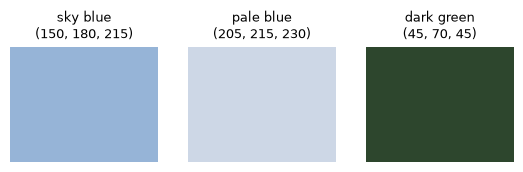

| Pair of reference colors   |   Lab distance d |   Similarity a |
|:---------------------------|-----------------:|---------------:|
| sky blue and pale blue     |            18.36 |          0.713 |
| sky blue and dark green    |            57.57 |          0.099 |
| pale blue and dark green   |            63.90 |          0.000 |

In [12]:
hazy = {"sky blue": (150, 180, 215), "pale blue": (205, 215, 230), "dark green": (45, 70, 45)}
hazy_lab = rgb_to_lab(np.array(list(hazy.values()), float))
A3 = similarity_matrix(hazy_lab)
D3 = np.linalg.norm(hazy_lab[:, None] - hazy_lab[None], axis=-1)

fig, axes = plt.subplots(1, 3, figsize=(6.5, 1.5))
for ax, (name, rgb) in zip(axes, hazy.items()):
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, color=np.array(rgb) / 255))
    ax.set_title(f"{name}\n{rgb}", fontsize=9)
    ax.axis("off")
plt.show()

hazy_names = list(hazy)
print_table([[f"{hazy_names[i]} and {hazy_names[j]}", D3[i, j], A3[i, j]] for i, j in [(0, 1), (0, 2), (1, 2)]],
            headers=["Pair of reference colors", "Lab distance d", "Similarity a"], floatfmt=(".0f", ".2f", ".3f"))

The query photo $\mathbf{h}$ is 60% sky blue and 40% dark green. Photo $\mathbf{g}$ shows the same
scene on a hazier day, so its sky has moved into the pale blue bin. Photo $\mathbf{k}$ shows a
forest with a little sky.

In [13]:
h_query = np.array([0.6, 0.0, 0.4])
candidates = {"g: the same scene, hazier sky": np.array([0.0, 0.6, 0.4]),
              "k: a forest with a little sky": np.array([0.2, 0.0, 0.8])}
print_table([[name, l1(h_query, x), quadratic(h_query, x, A3)] for name, x in candidates.items()],
            headers=["Compared with the query h", "L1 distance", "Quadratic distance"], floatfmt=("", ".1f", ".3f"))

| Compared with the query h     |   L1 distance |   Quadratic distance |
|:------------------------------|--------------:|---------------------:|
| g: the same scene, hazier sky |           1.2 |                0.207 |
| k: a forest with a little sky |           0.8 |                0.288 |

The L1 distance prefers the forest. The quadratic distance prefers the hazy sky: for
$\mathbf{h} - \mathbf{g} = (0.6, -0.6, 0)$, the two differences have opposite signs, and the
off-diagonal entry $a_{1,2} = 0.713$ lets them partly cancel. The values match the book.

### Histogram intersection: a palette query

A third measure serves a user who picks colors from a palette, such as "at least 30% light sky
blue and 20% white", and does not care about the rest of the image. The **histogram intersection**
measures how much of the query is contained in the image:

$$\delta_{\cap}(\mathbf{h}, \mathbf{g}) = \frac{\sum_{i=1}^{N} \min(h_i, g_i)}{\min\left(\sum_{i} h_i, \sum_{i} g_i\right)}$$

The query holds only the selected colors, so its entries sum to less than 1, and the result is a
similarity between 0 and 1. We place the palette in the 125-color Lab vocabulary: light sky blue
is the reference color at $L = 90, a = 0, b = -20$, white the one at $L = 90, a = 0, b = 0$.

In [14]:
def intersection(h, g):
    return float(np.minimum(h, g).sum() / min(h.sum(), g.sum()))

palette = np.zeros(len(centers))
palette[lab_bin(np.array([90.0, 0.0, -20.0]))] = 0.3      # 30% light sky blue
palette[lab_bin(np.array([90.0, 0.0, 0.0]))] = 0.2        # 20% white
print_table([[titles[n], intersection(h, palette)] for n, h in H.items()],
            headers=["Photo", "Palette query: 30% light sky blue, 20% white"], floatfmt=".2f")

| Photo         |   Palette query: 30% light sky blue, 20% white |
|:--------------|-----------------------------------------------:|
| Matterhorn    |                                           0.88 |
| Taj Mahal     |                                           0.06 |
| Roger Federer |                                           0.19 |

The Matterhorn photo matches the palette well. The Taj Mahal photo scores very low, although its
sky is clearly blue: its sky is darker and falls into the lightness ranges below.

### The three photos

The four measures applied to the 125-bin histograms of the three photos:

In [15]:
A = similarity_matrix(centers)                       # 125 x 125
q = H["matterhorn"]
print_table([[titles[n], l1(q, H[n]), l2(q, H[n]), intersection(q, H[n]), 1 - l1(q, H[n]) / 2, quadratic(q, H[n], A)]
             for n in ("taj_mahal", "federer")],
            headers=["Compared with the Matterhorn photo", "L1 distance", "L2 distance", "Intersection",
                     "1 - L1/2", "Quadratic distance"], floatfmt=".3f")

| Compared with the Matterhorn photo   |   L1 distance |   L2 distance |   Intersection |   1 - L1/2 |   Quadratic distance |
|:-------------------------------------|--------------:|--------------:|---------------:|-----------:|---------------------:|
| Taj Mahal                            |         1.361 |         0.461 |          0.320 |      0.320 |                0.079 |
| Roger Federer                        |         1.659 |         0.710 |          0.171 |      0.171 |                0.353 |

All measures rank the Taj Mahal closer to the Matterhorn than the Federer photo, but they differ
in how clearly. The bin-by-bin measures see two very different histograms in both cases: only
32% of the Taj Mahal histogram overlaps with the Matterhorn histogram. The column $1 - L1/2$
equals the intersection: for two complete histograms, which both sum to 1, the intersection ranks
images in the same order as the L1 distance. The quadratic distance accounts for the similarity of
neighboring bins and puts the Taj Mahal more than four times closer than the Federer photo.

The result is a success and a failure at the same time. The histogram works as designed, and it
returns a building when the query shows a mountain. Perceptual similarity is not semantic
similarity.

### The vocabulary changes the numbers

We repeat the comparison with the vocabularies of section 2. The quadratic distance needs the
Lab distance between the reference colors. It is defined for the RGB and Lab vocabularies, but
not for the hue vocabulary: a hue sector has no single Lab color, and the gray bin has no
position on the hue circle.

In [16]:
rows = []
for name, (f, colors, lab_centers) in vocabularies.items():
    hs = {n: histogram(f(photos[n]), len(colors)) for n in photos}
    if lab_centers is None:
        quad = ["not defined"] * 2
    else:
        A_v = similarity_matrix(lab_centers)
        quad = [f"{quadratic(hs['matterhorn'], hs[n], A_v):.3f}" for n in ("taj_mahal", "federer")]
    rows.append([name, len(colors)] + [f"{l1(hs['matterhorn'], hs[n]):.3f}" for n in ("taj_mahal", "federer")] + quad)
print_table(rows, headers=["Vocabulary", "Reference colors", "L1 to Taj Mahal", "L1 to Federer",
                           "Quadratic to Taj Mahal", "Quadratic to Federer"])

| Vocabulary                   |   Reference colors |   L1 to Taj Mahal |   L1 to Federer | Quadratic to Taj Mahal   | Quadratic to Federer   |
|:-----------------------------|-------------------:|------------------:|----------------:|:-------------------------|:-----------------------|
| RGB, 4 ranges per channel    |                 64 |             1.322 |           1.606 | 0.046                    | 0.170                  |
| Lab, ranges of 20 (the book) |                125 |             1.361 |           1.659 | 0.079                    | 0.353                  |
| Lab, ranges of 10            |               1000 |             1.681 |           1.811 | 0.067                    | 0.291                  |
| Hue, 7 sectors plus gray     |                  8 |             0.589 |           1.489 | not defined              | not defined            |

All vocabularies agree on the order. They disagree on the size of the gap. With ranges of 10
instead of 20 Lab units, the L1 distances grow: more reference colors mean more bin boundaries,
and more pixels end up on the other side of one. The quadratic distance changes much less,
because it charges little for a pixel that moves to a neighboring reference color.

## 4. Color Moments

A histogram with 125 bins is a long vector. **Color moments** summarize the distribution of each
channel with four statistics instead: the mean $\mu_c$ (position), the standard deviation
$\sigma_c$ (width), the skewness $s_c$ (asymmetry), and the kurtosis $k_c$ (weight in the tails).

$$\mu_c = \frac{1}{NM} \sum_{x,y} c(x,y) \qquad \sigma_c = \sqrt{\frac{1}{NM} \sum_{x,y} \big(c(x,y) - \mu_c\big)^2}$$

$$s_c = \frac{1}{NM} \sum_{x,y} \left(\frac{c(x,y) - \mu_c}{\sigma_c}\right)^3 \qquad k_c = \frac{1}{NM} \sum_{x,y} \left(\frac{c(x,y) - \mu_c}{\sigma_c}\right)^4$$

Four moments for each of the three Lab channels plus the three covariances between the channel
pairs give a feature vector of 15 values.

In [17]:
MOMENT_NAMES = ([f"mean {c}" for c in "Lab"] + [f"std {c}" for c in "Lab"] + [f"skewness {c}" for c in "Lab"]
                + [f"kurtosis {c}" for c in "Lab"] + ["cov L,a", "cov L,b", "cov a,b"])

def color_moments(lab):
    """15 values: mean, standard deviation, skewness, and kurtosis of L, a, and b, and the three covariances."""
    x = lab.reshape(-1, 3)
    mu, sd = x.mean(0), x.std(0)
    z = (x - mu) / sd
    cov = (x - mu).T @ (x - mu) / len(x)
    return np.concatenate([mu, sd, (z ** 3).mean(0), (z ** 4).mean(0), [cov[0, 1], cov[0, 2], cov[1, 2]]])

moments = {n: color_moments(l) for n, l in lab.items()}
print_table([[name] + [moments[n][i] for n in photos] for i, name in enumerate(MOMENT_NAMES)],
            headers=["Moment"] + [titles[n] for n in photos], floatfmt=".2f")

| Moment     |   Matterhorn |   Taj Mahal |   Roger Federer |
|:-----------|-------------:|------------:|----------------:|
| mean L     |        60.95 |       47.11 |           55.64 |
| mean a     |        -0.66 |       -3.12 |          -10.86 |
| mean b     |       -11.54 |       -0.55 |           29.43 |
| std L      |        32.08 |       21.66 |           15.82 |
| std a      |         4.63 |        8.18 |           12.10 |
| std b      |        10.27 |       18.22 |           17.12 |
| skewness L |        -0.37 |       -0.51 |            0.16 |
| skewness a |        -1.17 |        1.11 |            1.08 |
| skewness b |         1.09 |        0.18 |           -1.08 |
| kurtosis L |         1.47 |        2.51 |            4.60 |
| kurtosis a |         6.63 |        5.58 |            3.59 |
| kurtosis b |         4.97 |        2.21 |            2.62 |
| cov L,a    |        19.76 |        8.05 |          -20.49 |
| cov L,b    |       -42.48 |      -96.44 |          -95.95 |
| cov a,b    |       -35.51 |       29.99 |         -143.01 |

The numbers read like a description. The Matterhorn photo has a blue cast (mean $b$ is
negative), almost no green or red tint (mean $a$ near zero), and the strongest contrast of the
three (the largest standard deviation of $L$), from the bright sky and snow to the dark forest.
The Federer photo is green (negative $a$) and yellow (positive $b$): the color of grass. The
negative covariance of $L$ and $b$ in the Matterhorn photo says: the brighter a pixel, the bluer it
is, because the brightest large region is the sky.

### Rescaling before comparing

The moments have very different value ranges: the skewness lies around 1, the covariances reach
into the hundreds. A Euclidean distance on the raw vectors is dominated by the largest values.
The Gaussian normalization of Chapter 6 divides each dimension by its standard deviation over
the collection. Our collection has only the three photos, which is enough to show the effect but
too small for a reliable scale. The book names two shorter variants: the four moments of the
lightness alone, and the moments of the two chromaticity channels $a$ and $b$ (8 values plus
their covariance, 9 in total).

In [18]:
scale = np.std([moments[n] for n in photos], axis=0)          # per dimension, over the collection
SUBSETS = {"all 15": list(range(15)),
           "L only (4)": [0, 3, 6, 9],
           "a and b (9)": [1, 2, 4, 5, 7, 8, 10, 11, 14]}

def moment_distance(p, q, dims):
    return float(np.linalg.norm(((p - q) / scale)[dims]))

rows = []
for n in ("taj_mahal", "federer"):
    d = moments["matterhorn"] - moments[n]
    rows.append([titles[n], np.linalg.norm(d), (d[12:] ** 2).sum() / (d ** 2).sum()]
                + [moment_distance(moments["matterhorn"], moments[n], dims) for dims in SUBSETS.values()])
print_table(rows, headers=["Compared with the Matterhorn photo", "Raw distance", "Share from the covariances"]
                          + [f"Normalized, {s}" for s in SUBSETS], floatfmt=("", ".1f", ".0%", ".2f", ".2f", ".2f"))

| Compared with the Matterhorn photo   |   Raw distance |   Share from the covariances |   Normalized, all 15 |   Normalized, L only (4) |   Normalized, a and b (9) |
|:-------------------------------------|---------------:|-----------------------------:|---------------------:|-------------------------:|--------------------------:|
| Taj Mahal                            |           88.6 |                          93% |                 5.80 |                     3.03 |                      4.41 |
| Roger Federer                        |          135.1 |                          88% |                 8.31 |                     3.98 |                      6.57 |

On the raw vectors, the three covariances contribute about nine tenths of the squared distance,
and the other twelve moments hardly count. After the normalization, every dimension counts on
the same scale. All variants rank the Taj Mahal closer than the Federer photo, as the histograms
do.

### A distribution with two peaks

Moments are compact: 15 values instead of 125 to 1000 bins, and no matrix between bins. Their
weakness is that a few statistics cannot describe a distribution with several peaks.

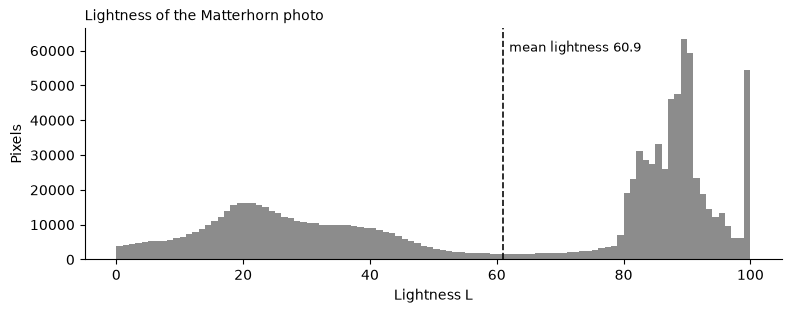

Only **1.6%** of the pixels have a lightness within 5 units of the mean.

In [19]:
L_m = lab["matterhorn"][..., 0].ravel()
near_mean = (np.abs(L_m - L_m.mean()) < 5).mean()

fig, ax = plt.subplots(figsize=(9, 3))
ax.hist(L_m, bins=100, range=(0, 100), color="#8c8c8c")
ax.axvline(L_m.mean(), color="#0b0b0b", ls="--", lw=1.2)
ax.text(L_m.mean() + 1, ax.get_ylim()[1] * 0.9, f"mean lightness {L_m.mean():.1f}", fontsize=9)
ax.set_xlabel("Lightness L")
ax.set_ylabel("Pixels")
ax.set_title("Lightness of the Matterhorn photo", fontsize=10, loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.show()
display_md(f"Only **{near_mean:.1%}** of the pixels have a lightness within 5 units of the mean.")

The bright sky and snow and the dark forest form two peaks. Their mean lies in the valley between
them, at a lightness that few pixels actually have.

## 5. What Global Color Features Miss

Histograms and moments ignore where a color occurs. Shuffling the pixels of an image produces a
meaningless image with exactly the same features.

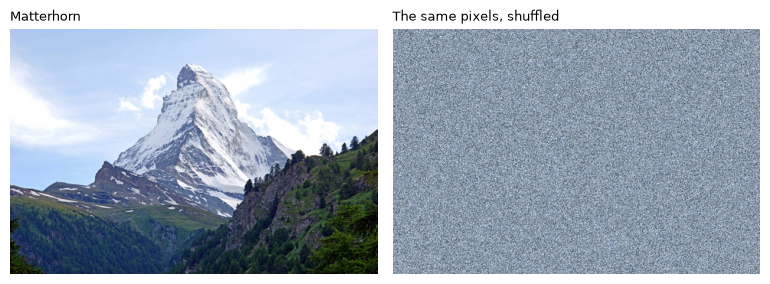

| Feature | Matterhorn compared with its shuffled copy |
|---|---|
| L1 distance of the Lab histograms | 0.000 |
| Largest difference among the 15 moments | 6.1e-11 |

In [20]:
rng = np.random.default_rng(0)
shuffled = rng.permutation(m.reshape(-1, 3)).reshape(m.shape)     # the same pixels in random positions
lab_shuffled = rgb_to_lab(shuffled)

show_images([thumbnail(m), thumbnail(shuffled)], ["Matterhorn", "The same pixels, shuffled"])
display_md(f"| Feature | Matterhorn compared with its shuffled copy |\n|---|---|\n"
           f"| L1 distance of the Lab histograms | {l1(H['matterhorn'], histogram(lab_bin(lab_shuffled), 125)):.3f} |\n"
           f"| Largest difference among the 15 moments | {np.abs(moments['matterhorn'] - color_moments(lab_shuffled)).max():.1e} |")

The histograms are identical. The moments differ only by floating-point rounding, because the
sums run over the pixels in a different order.

A simple remedy keeps a little layout information. Stricker and Dimai proposed in 1996 to split
the image into five regions, an ellipse in the center and the four corners, to compute color
moments per region, and to weight the center more strongly. We use a simplified version: crisp
regions instead of overlapping ones, an ellipse that spans 75% of the width and the height, and
only the mean Lab color per region. The distance between two images is the Lab distance between
their region colors, averaged over the regions with weight 2 for the center.

In [21]:
def regions(shape):
    """Five regions: a central ellipse and the four corners outside it (crisp borders)."""
    h, w = shape[:2]
    y, x = np.mgrid[:h, :w]
    ellipse = ((x - w / 2) / (0.375 * w)) ** 2 + ((y - h / 2) / (0.375 * h)) ** 2 <= 1
    top, left = y < h / 2, x < w / 2
    return {"center": ellipse, "top left": ~ellipse & top & left, "top right": ~ellipse & top & ~left,
            "bottom left": ~ellipse & ~top & left, "bottom right": ~ellipse & ~top & ~left}

def region_colors(lab):
    """Mean Lab color of each region, an array of 5 x 3."""
    return np.array([lab[r].mean(0) for r in regions(lab.shape).values()])

def region_distance(p, q, center_weight=2.0):
    w = np.array([center_weight, 1, 1, 1, 1])
    return float((w * np.linalg.norm(p - q, axis=1)).sum() / w.sum())

R_m, R_s = region_colors(lab["matterhorn"]), region_colors(lab_shuffled)
print_table([[name, R_m[i, 0], R_s[i, 0], R_m[i, 2], R_s[i, 2]] for i, name in enumerate(regions(m.shape))],
            headers=["Region", "Mean L, Matterhorn", "Mean L, shuffled", "Mean b, Matterhorn", "Mean b, shuffled"],
            floatfmt=".1f")

| Region       |   Mean L, Matterhorn |   Mean L, shuffled |   Mean b, Matterhorn |   Mean b, shuffled |
|:-------------|---------------------:|-------------------:|---------------------:|-------------------:|
| center       |                 66.7 |               61.0 |                -11.8 |              -11.5 |
| top left     |                 87.2 |               61.0 |                -15.2 |              -11.5 |
| top right    |                 87.2 |               60.9 |                -14.0 |              -11.6 |
| bottom left  |                 33.1 |               61.0 |                -18.3 |              -11.5 |
| bottom right |                 17.7 |               60.9 |                  2.1 |              -11.5 |

In the original photo, the top corners are bright sky and the bottom corners dark forest. In the
shuffled copy, every region has the average color of the whole photo. Such region features
remain cheap and work well for photos with a typical composition.

## Payoff: Which Differences Does a Feature Ignore?

We now send the Matterhorn photo as a query against four candidates. Two of them are copies of
the query: the darker copy shows the same scene with less light, so a user would want it near the
top; the shuffled copy contains no scene at all. The other two are the Taj Mahal and the Federer
photos. For each feature we compute the distance from the query to every candidate and the
resulting ranking.

In [22]:
cand_rgb = {"shuffled copy": shuffled, "darker copy": darker,
            "Taj Mahal": photos["taj_mahal"], "Roger Federer": photos["federer"]}
cand_lab = {"shuffled copy": lab_shuffled, "darker copy": lab_d,
            "Taj Mahal": lab["taj_mahal"], "Roger Federer": lab["federer"]}

hue_hist = lambda rgb: histogram(hue_bin(rgb), 8)
q_lab, q_hue, q_mom, q_reg = H["matterhorn"], hue_hist(m), moments["matterhorn"], region_colors(lab["matterhorn"])
features = {
    "Lab histogram, L1": lambda c: l1(q_lab, histogram(lab_bin(cand_lab[c]), 125)),
    "Lab histogram, quadratic": lambda c: quadratic(q_lab, histogram(lab_bin(cand_lab[c]), 125), A),
    "Hue histogram, L1": lambda c: l1(q_hue, hue_hist(cand_rgb[c])),
    "Moments, all 15": lambda c: moment_distance(q_mom, color_moments(cand_lab[c]), SUBSETS["all 15"]),
    "Moments, a and b (9)": lambda c: moment_distance(q_mom, color_moments(cand_lab[c]), SUBSETS["a and b (9)"]),
    "Region colors": lambda c: region_distance(q_reg, region_colors(cand_lab[c])),
}

rows = []
for name, dist in features.items():
    d = {c: dist(c) for c in cand_rgb}
    ranking = sorted(d, key=d.get)
    rows.append([name] + [d[c] for c in cand_rgb] + [ranking.index("darker copy") + 1, ", ".join(ranking)])
print_table(rows, headers=["Feature"] + [f"Distance to {c}" for c in cand_rgb] + ["Rank of the darker copy", "Ranking"],
            floatfmt=".3f")

| Feature                  |   Distance to shuffled copy |   Distance to darker copy |   Distance to Taj Mahal |   Distance to Roger Federer |   Rank of the darker copy | Ranking                                              |
|:-------------------------|----------------------------:|--------------------------:|------------------------:|----------------------------:|--------------------------:|:-----------------------------------------------------|
| Lab histogram, L1        |                       0.000 |                     1.299 |                   1.361 |                       1.659 |                         2 | shuffled copy, darker copy, Taj Mahal, Roger Federer |
| Lab histogram, quadratic |                       0.000 |                     0.140 |                   0.079 |                       0.353 |                         3 | shuffled copy, Taj Mahal, darker copy, Roger Federer |
| Hue histogram, L1        |                       0.000 |                     0.072 |                   0.589 |                       1.489 |                         2 | shuffled copy, darker copy, Taj Mahal, Roger Federer |
| Moments, all 15          |                       0.000 |                     4.757 |                   5.802 |                       8.314 |                         2 | shuffled copy, darker copy, Taj Mahal, Roger Federer |
| Moments, a and b (9)     |                       0.000 |                     1.363 |                   4.414 |                       6.566 |                         2 | shuffled copy, darker copy, Taj Mahal, Roger Federer |
| Region colors            |                      23.127 |                    23.420 |                  26.107 |                      52.007 |                         2 | shuffled copy, darker copy, Taj Mahal, Roger Federer |

<div style="border-left: 4px solid #C8102E; background: rgba(200, 16, 46, 0.06); padding: 0.6em 0.9em; margin: 0.6em 0; border-radius: 4px;">
<strong style="color:#C8102E; text-transform:uppercase; font-size:0.78em; letter-spacing:0.06em;">A feature decides which differences to ignore</strong><br>
The five global features put the shuffled copy first, at distance 0, because they ignore where the pixels lie. The region colors see the difference, but they still rank the shuffled copy first, just ahead of the darker copy. The features without lightness, the hue histogram and the moments of <em>a</em> and <em>b</em>, keep the darker copy well ahead of the Taj Mahal. The quadratic Lab distance even ranks the Taj Mahal before the darker copy of the query itself.<br><br>No feature here ignores exactly the differences a user would ignore. Each one finds images that look alike in one respect, which is not the same as images that show the same thing.
</div>

## Summary

- sRGB distances do not match perceived differences. Lab does, approximately, but only if the
  conversion undoes the gamma encoding first. Without that step, the distances are wrong without
  any warning.
- HSV separates the hue from the brightness, so a hue feature ignores a shadow. Nearly gray and
  very dark pixels have no meaningful hue and must be treated as gray.
- A color histogram counts pixels per reference color. The vocabulary decides what it can tell
  apart: the Taj Mahal's darker sky lands in different bins from the Matterhorn's sky.
- L1 and L2 compare bin by bin and react strongly to bin boundaries. The quadratic distance
  charges little for a move to a similar color. The intersection answers palette queries and,
  for complete histograms, ranks like L1.
- 15 color moments describe a photo compactly but need rescaling, and they cannot describe a
  distribution with two peaks.
- Global color features ignore the layout. Region features keep a little of it, and no color
  feature knows what the photo shows.

## Try it yourself

1. **The book's HSV vocabulary.** Extend `hue_bin` with nine ranges of the value $V$, which gives
   the $7 \times 9 = 63$ reference colors of the book (keep the gray bin, or split it into gray
   levels). Rerun the payoff. Where does the darker copy rank now, and why?
2. **A colored shadow.** Light in the shade comes from the blue sky. Replace the darker copy by
   `np.round(m * [0.55, 0.6, 0.7]).astype(np.uint8)` and rerun the shade table and the payoff.
   Which features still keep the copy close?
3. **The thresholds for gray.** Change `GRAY_S` to 0.05 or 0.3 and rerun the hue view and the
   payoff. How much of the Matterhorn sky counts as gray, and how does the hue histogram change?